<a href="https://colab.research.google.com/github/Gabejevans/California-Housing-Project/blob/main/CaliforniaHousing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **California Housing Project**

Can we improve predictions on California house prices using feauture engineering and parameter tuning using a nueral network?

This project will investigate SKlearns California housing dataset to see if feature engineering can improve performance on predicting house prices with a Neural Network and an ensembed HistGradient Boosting model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#### **1) Load Data from SKLearn**

The dataset used will use SKLearns California Housing dataset, this consists of 20,640 samples and 9 features relating to aggregated groups of houses in geographical areas in California.

In [2]:
data = fetch_california_housing(as_frame = True)
data_view = pd.DataFrame(data.data, columns = data.feature_names)
data_view.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [3]:
data = fetch_california_housing(as_frame = True)
data_view = pd.DataFrame(data.data, columns = data.feature_names)
data_view.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


#### **2) View the Data**

In [4]:
print("Dataset information:")
display(data_view.info())
print("Dataset Statistical Spread:")
display(data_view.describe())
print("Null Values In the Dataset:")
display(data_view.isnull().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB


None

Dataset Statistical Spread:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


Null Values In the Dataset:


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0


The data contains no null values so we won't have to handle any nulls. However the data does look reasonably right skewed on quite a few feautures, namely Population and AveOccup , this suggests it could be beneficial to apply some scaling to the model.

#### **3) Visualisations**

In [5]:
#combine target and data
data_combined = pd.concat([data_view, data.target], axis=1)
data_combined.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


##### **3.1) Geospatial Visualisations**

The location of the houses could be a big indicator of price and displays the spread of the data in the california region

##### **3.1.1) View Data Points on the Map**

In [6]:
import folium
from folium.plugins import MarkerCluster
import matplotlib.pyplot as plt
import matplotlib.colors as colors

# Create a map centered around London
m = folium.Map(location=[36.7783, -119.4179], zoom_start=10, tiles='CyclOSM')

# Create a MarkerCluster to add multiple markers
marker_cluster = MarkerCluster().add_to(m)

norm = colors.Normalize(vmin=data_combined["MedHouseVal"].min(), vmax=data_combined["MedHouseVal"].max())

# Add markers with colour proportional to House Values
for index, row in data_combined.iterrows():
    color = plt.cm.jet(norm(row['MedHouseVal']))
    color_hex = colors.rgb2hex(color)
    folium.CircleMarker(location=[row['Latitude'], row['Longitude']],
                        color=color_hex,
                        fill_color=color_hex,
                        fill_opacity=0.5,
                        #displays MedHouseVal onto the map
                        popup=f"MedHouseVal: {row['MedHouseVal']:,.2f}").add_to(marker_cluster)

# Display the map
m

we can see that we have large clusters of data around major cities such as San Francisco and LA, these could be important features to include in the data to help with the model with geospatial information.

##### **3.1.2) House Price by Area**

In [7]:
import geopandas as gpd
from shapely.geometry import Point

coast = gpd.read_file(
    "https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip"
)

#restrict coatline to califorias borders
coast = coast.cx[-125:-114, 32:42]

#convert to California Albers (metres)
coast = coast.to_crs("EPSG:3310")

#combine californias coastline geometry
coastline = coast.geometry.union_all()

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: GDAL was built against curl 8.20.0, but is running against 8.11.0. Runtime failure is likely !
  return ogr_read(


In [8]:
import numpy as np
from math import radians, sin, cos, asin, sqrt

cities = {
    "Los Angeles": (34.0522, -118.2437),
    "Bay Area": (37.65, -122.15),
    "Sacramento": (38.5816, -121.4944),
    "San Diego": (32.7157, -117.1611),
    "Fresno": (36.7378, -119.7871)
}

#Classifying The data into key areas for Visualisation.
def classify_area(lat, lon, radius=20):

    # Calculate distance from each city (Haversine)
    for city, (city_lat, city_lon) in cities.items():

        lat1, lon1 = radians(lat), radians(lon)
        lat2, lon2 = radians(city_lat), radians(city_lon)

        dlat = lat2 - lat1
        dlon = lon2 - lon1

        a = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2
        distance = 3958.8 * 2 * asin(sqrt(a))

        if distance <= radius:
            return city

    # Calculate distance from coastline
    point = gpd.GeoSeries(
        [Point(lon, lat)],
        crs="EPSG:4326"
    ).to_crs("EPSG:3310").iloc[0]

    coast_distance = point.distance(coastline) / 1609.344

    if coast_distance <= radius:
        return "Coastal"

    return "Countryside"

In [9]:
data_combined["Area"] = data_combined.apply(
    lambda row: classify_area(
        row["Latitude"],
        row["Longitude"]
    ),
    axis=1
)

In [10]:
housing_by_area = (data_combined
                   .groupby("Area")["MedHouseVal"]
                   .mean()
                   .reset_index()
)

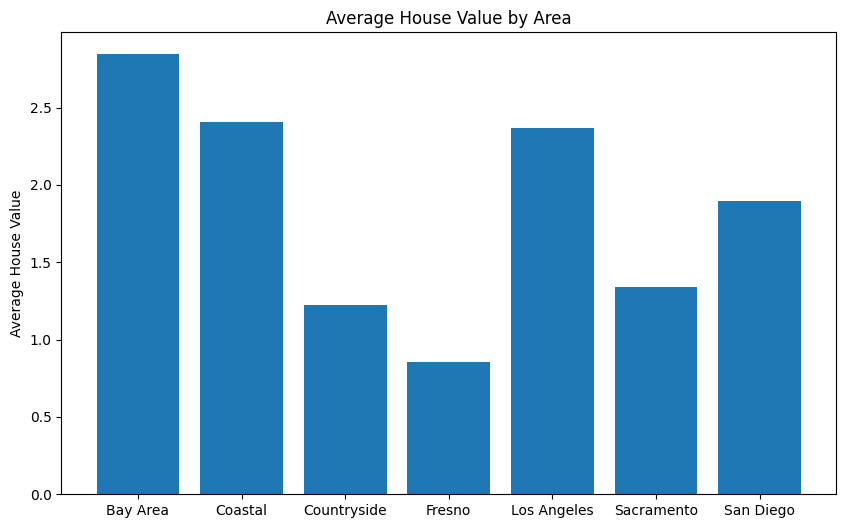

In [11]:
plt.figure(figsize=(10, 6))
plt.bar(housing_by_area["Area"], housing_by_area["MedHouseVal"])
plt.ylabel("Average House Value")
plt.title("Average House Value by Area")
plt.show()

From the bar plot is clear to see that area has a big sway on the price of houses, San Francisco and LA clearly being the most expensive cities and coastal properties also being more expensive. Smaller cities and non coastal countryside are the least expensive areas. Area will be an important feature, i can apply a feature icluding area using a one hot encoder or use a few distance based features.

#### **3.2) Other Features**

Lets look at the numerical features relating to each house and see how they could effect HousePrices in each region.

In [12]:
data_combined.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,Area
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,Bay Area
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,Bay Area
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,Bay Area
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,Bay Area
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,Bay Area


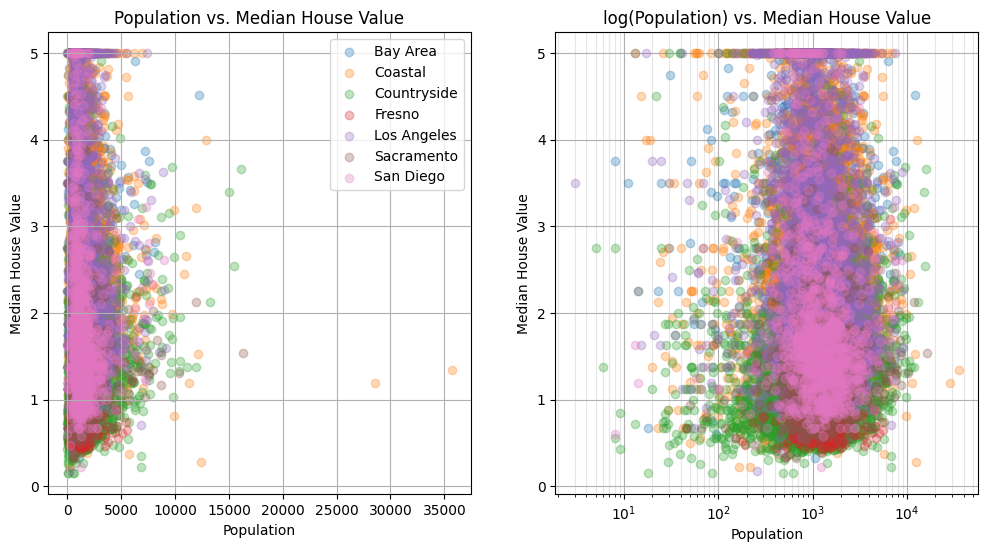

In [13]:
### House price vs population

fig, axs = plt.subplots( 1,2 , figsize=(12, 6))

for area in data_combined["Area"].unique():
    mask = data_combined["Area"] == area

    axs[0].scatter(
        data_combined.loc[mask, "Population"],
        data_combined.loc[mask, "MedHouseVal"],
        alpha=0.3,
        label=area
    )

    axs[1].semilogx(
        data_combined.loc[mask, "Population"],
        data_combined.loc[mask, "MedHouseVal"],
        'o',
        alpha=0.3,
        label=area
    )

axs[0].legend()
axs[0].set_xlabel("Population")
axs[0].set_ylabel("Median House Value")
axs[0].set_title("Population vs. Median House Value")
axs[0].grid()
axs[1].set_xlabel("Population")
axs[1].set_ylabel("Median House Value")
axs[1].set_title("log(Population) vs. Median House Value")
axs[1].grid()
axs[1].grid(which = "minor", color = "0.9")

plt.show()

Affects of logging the Population distribution can be seen above. The first plot depicts a very right skewed distribution, taking the log centers our distribution and will give the model more resolveable information about the data

##### **3.2.2) Median House Price vs Feature Plots**

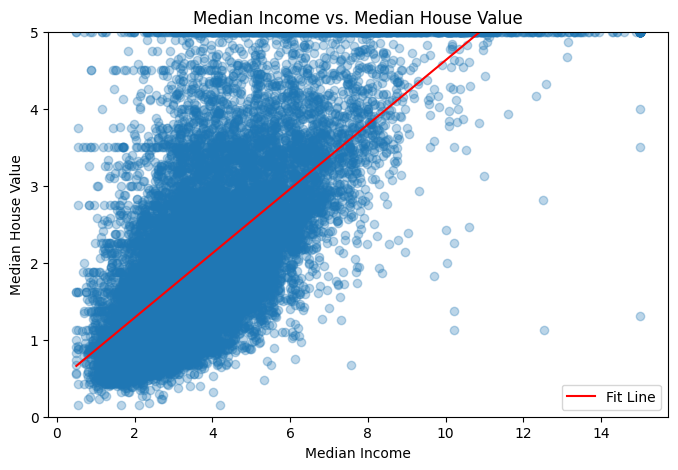

In [14]:
### median income vs house price
# create line of best fit
slope, intercept = np.polyfit(data_combined["MedInc"], data_combined["MedHouseVal"], 1)
x = np.linspace(data_combined["MedInc"].min(), data_combined["MedInc"].max(), 100)
y = slope * x + intercept

#plot the data
plt.figure(figsize=(8, 5))
plt.scatter(data_combined["MedInc"], data_combined["MedHouseVal"], alpha = 0.3)
plt.plot(x, y, color = "red", label="Fit Line")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.ylim(0,5)
plt.title("Median Income vs. Median House Value")
plt.legend()
plt.show()

We can see that median income will be a strong indicator of house price. This is logical as people with higher incomes are likely to have more expensive houses

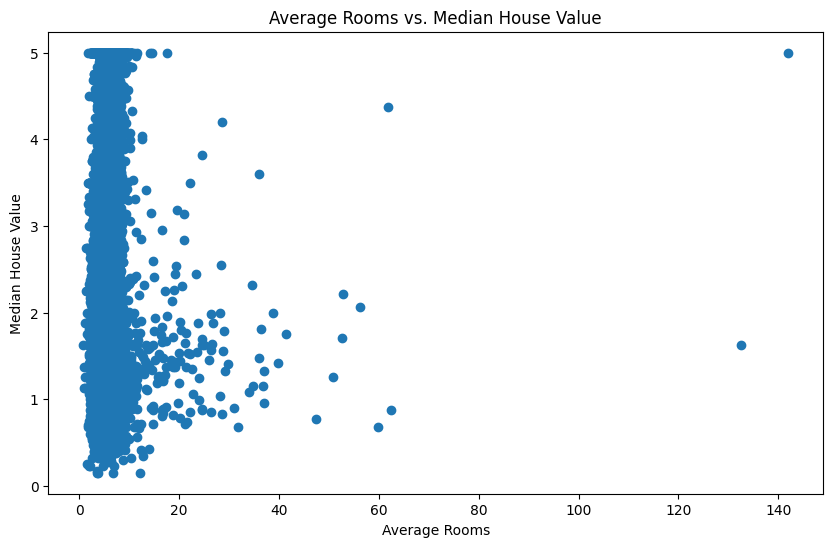

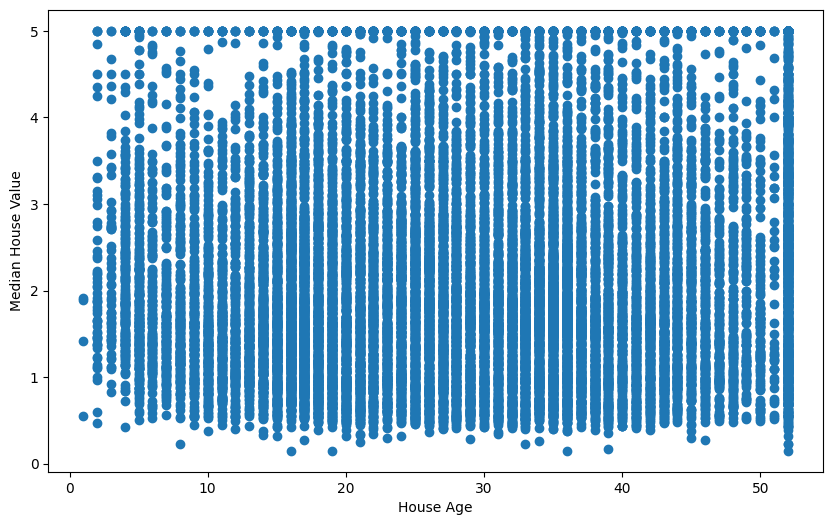

In [15]:
### average rooms vs house price
plt.figure(figsize=(10, 6))
plt.scatter(data_combined["AveRooms"], data_combined["MedHouseVal"])
plt.xlabel("Average Rooms")
plt.ylabel("Median House Value")
plt.title("Average Rooms vs. Median House Value")
plt.show()

### house age
plt.figure(figsize=(10, 6))
plt.scatter(data_combined["HouseAge"], data_combined["MedHouseVal"])
plt.xlabel("House Age")
plt.ylabel("Median House Value")
plt.show()

population seems to be reasonably week indicator of house price here along with number of rooms. Medium income however seems to show a strong correlation with house price, this suggest that it will be a strong feature for the model to learn from. House Age doesn't seem to have much of an effect on the prices with an even spread of data on House Age vs Median House Price

Rooms per person could be a good indicator of house layout.

In [16]:
data_combined["RoomsPerPerson"] = data_combined["AveRooms"] / data_combined["AveOccup"]
display(data_combined[data_combined["AveRooms"] > 50].head())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,Area,RoomsPerPerson
1912,4.9750,16.0,56.269231,10.153846,54.0,2.076923,39.01,-120.16,2.06300,Countryside,27.092593
1913,4.0714,19.0,61.812500,11.000000,112.0,2.333333,39.01,-120.06,4.37500,Countryside,26.491071
1914,1.8750,33.0,141.909091,25.636364,30.0,2.727273,38.91,-120.10,5.00001,Countryside,52.033333
1979,4.6250,34.0,132.533333,34.066667,36.0,2.400000,38.80,-120.08,1.62500,Countryside,55.222222
2395,3.8750,23.0,50.837838,10.270270,64.0,1.729730,37.12,-119.34,1.25000,Countryside,29.390625


It's clear theres some outliers to the rooms perperson trend, possibly large houses in the countryside, maybe hotels? or farmouses

can look at smaller values

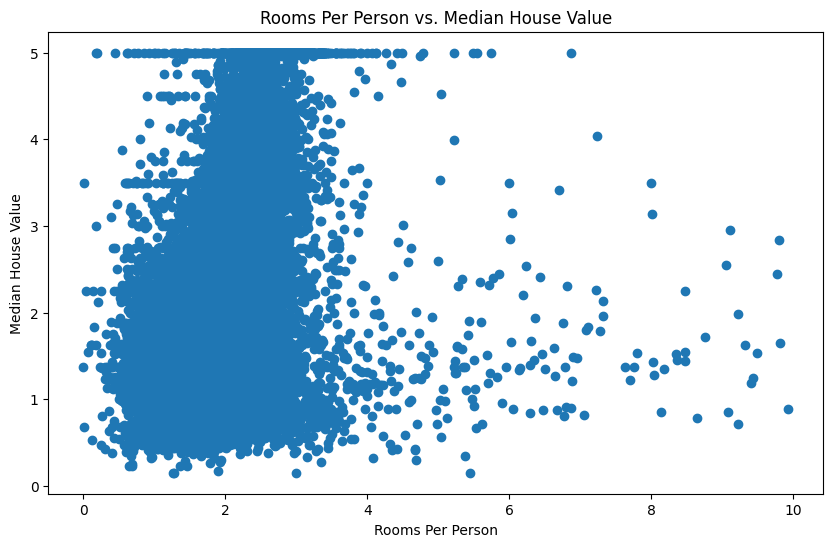

In [17]:
### rooms per person
mask = data_combined["RoomsPerPerson"] < 10
plt.figure(figsize=(10, 6))
plt.scatter(data_combined[mask]["RoomsPerPerson"], data_combined[mask]["MedHouseVal"])
plt.xlabel("Rooms Per Person")
plt.title("Rooms Per Person vs. Median House Value")
plt.ylabel("Median House Value")
plt.show()

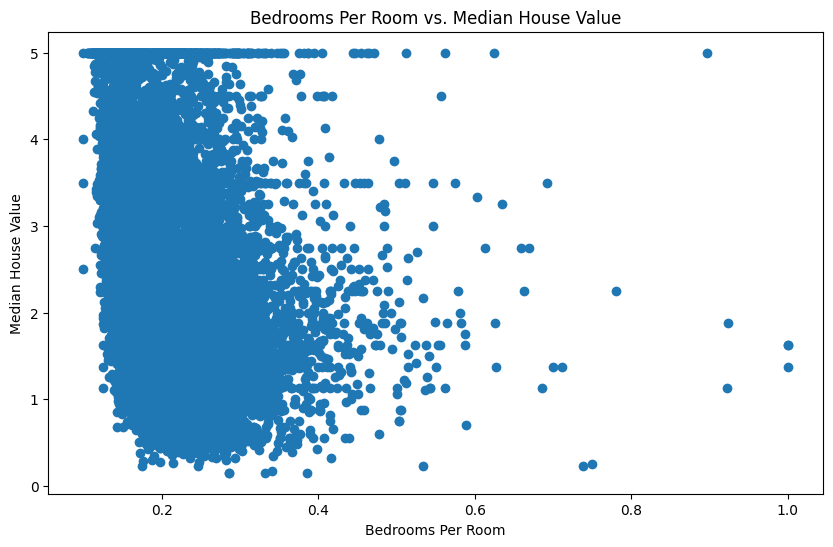

In [18]:
### bedroom ratio
data_combined["BedroomsPerRoom"] = data_combined["AveBedrms"] / data_combined["AveRooms"]

### plot
plt.figure(figsize=(10, 6))
plt.scatter(data_combined["BedroomsPerRoom"], data_combined["MedHouseVal"])
plt.xlabel("Bedrooms Per Room")
plt.ylabel("Median House Value")
plt.title("Bedrooms Per Room vs. Median House Value")
plt.show()

Bedrooms per room does look to have a relationship with houseprice so this could also be an interesting feature to add in giving the model information about house layout.

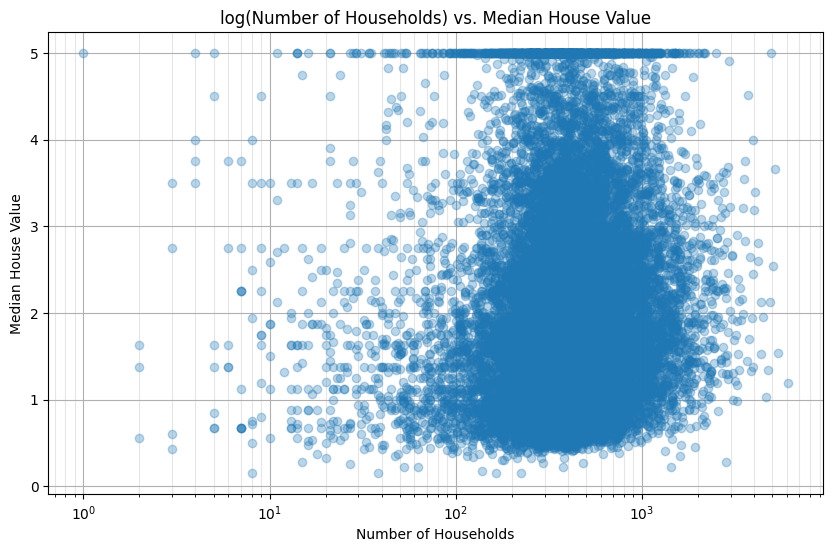

In [19]:
### number of households
data_combined["NumberOfHouseholds"] = data_combined["Population"] / data_combined["AveOccup"]

### plot
plt.figure(figsize=(10, 6))
plt.semilogx(data_combined["NumberOfHouseholds"], data_combined["MedHouseVal"], 'o', alpha = 0.3)
plt.xlabel("Number of Households")
plt.ylabel("Median House Value")
plt.grid()
plt.grid(which = "minor", color = "0.9")
plt.title("log(Number of Households) vs. Median House Value")
plt.show()

I think for my engineered features, the geospatial features are going to be very important, involving distances to the coast and major cities. For Nueral networks it takes a lot of learning to pick on geographical feature when compared to models such as HistGradientBoost so helpin it with these features will be imprtant in closing the gap on tree based models. For further engineered features total households seems useful as well as bedrooms per household. we can also look to engineer a feature looking at surrounding house prices

The surrounding house price feature will have to be created out of fold after splitting the data to prevent data leakage and ensure we are only using the train dataset.

In [20]:
X = data.data
y = data.target

In [21]:
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


### **4) Engineering Features**

When engineering features it's important to consider what each feature will tell the model and if there's any complications in adding it

We need to consider the domain, with this dataset we have already seen that MedInc has a strong correlation with houseprice along with geographical locations. Each feature should have a logical reason for existing otherwise it might not actually help the model to learn.

It's also important to consider possible sources of data leakage, this could be if we are using information derived from the target, whether future/unseen information is seen or are features inadventedly revealing the target.

Features may also have to be scaled if they have a very large distribution or are heavily skewed.

Feature engineering can introduce heavily correlated features increasing the liklehood that features become redundant which can add to model complexity and potentially cause overfitting.

Each feature implemented will be discussed considering these factors.

##### **4.1) Distance From the Coast**

Distance from the coast will be an important feature, we can see a clear difference between countryside and coastal house prices in the visualisations however our original coastal feature didn't account for how far away from the coast places were apart from the 20 mile split. This feature gives a comprehensive gradient of distance from the California coastline.

In [22]:
# Calculate distance from coastline
def DistCoast(lat, lon):
    point = gpd.GeoSeries(
        [Point(lon, lat)],
        crs="EPSG:4326"
    ).to_crs("EPSG:3310").iloc[0]

    coast_distance = point.distance(coastline) / 1609.344

    return coast_distance

##### **4.2 Distance From San Francisco, San Diego and Los Angeles**

These are our biggest cities, seeing the largest price increases so a feature representing distance from them will be useful, this opposed to the area grouping proposed before will offer a distance metric within the cities, houses closer to the center may be more expensive than the suburbs, that info will be preserved. Fresno and Sacramento didn't see to differ too much from the countryside and so they won't be included.

In [23]:
#define function for calculating harvestine distance
def haversine_km(lat1, lon1, lat2, lon2):
    # all inputs in radians
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

#define coordinates of the city
cities = {
    "SF":        (37.7749, -122.4194),
    "LA":        (34.0522, -118.2437),
    "SanDiego": (32.7157, -117.1611),
}


##### **4.3) Other Features Selected**
- Rooms per person, this will give the model an idea of the size of house owned by each household, although it will be subject to large outliers due to these large roomed houses viewed in the scatter plots.

- Bedrooms per room, this gives the model a feel for the house layout, if there's lots of rooms but not many bedrooms large mansion/workplace it could be a different style of house to a multi bedroom property, hotel/student accomodation.

- Number of households in the record is a feature to do with population densiy surrounding the properties. You'd assume lower number of households would represent a more spread out population. The population density will also be explored with a nearest neighbors distance feature after splitting the data.

After splitting the data a fe Nearest Neighbors based features will also be added and discussed.

In [24]:
def engineered_features(df):
    df["RoomsPerPerson"] = df["AveRooms"] / df["AveOccup"]
    df["BedroomsPerRoom"] = df["AveBedrms"] / df["AveRooms"]
    df["NumberOfHouseholds"] = df["Population"] / df["AveOccup"]


    df["DistCoast"] = df.apply(
        lambda row: DistCoast(
            row["Latitude"],
            row["Longitude"]
        ),
        axis=1
    )

    lat = np.radians(X["Latitude"].to_numpy())
    lon = np.radians(X["Longitude"].to_numpy())

    for name, (clat, clon) in cities.items():
      df[f"Dist{name}"] = haversine_km(lat, lon, np.radians(clat), np.radians(clon))
    return df

In [25]:
X = engineered_features(X)
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,RoomsPerPerson,BedroomsPerRoom,NumberOfHouseholds,DistCoast,DistSF,DistLA,DistSanDiego
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,2.732919,0.146591,126.0,4.201358,20.329542,556.531199,735.504257
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,2.956685,0.155797,1138.0,4.450429,19.908065,554.281885,733.239331
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,2.957661,0.129516,177.0,3.244449,17.835390,554.612739,733.528120
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,2.283154,0.184458,219.0,2.708987,17.064123,555.196283,734.097724
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,2.879646,0.172096,259.0,2.708987,17.064123,555.196283,734.097724


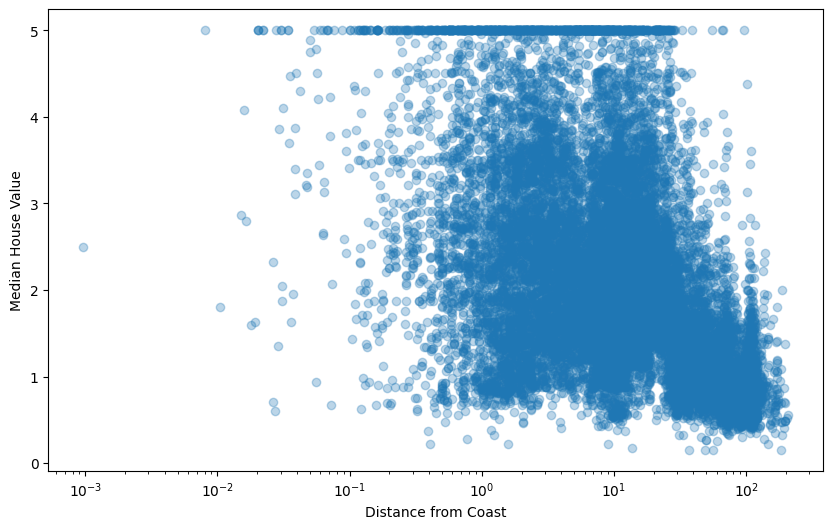

In [26]:
###plot coastal feature
plt.figure(figsize=(10, 6))
plt.semilogx(X["DistCoast"], y, 'o', alpha=0.3)
plt.xlabel("Distance from Coast")
plt.ylabel("Median House Value")
plt.show()

#### **5) Split Data into Train Test and Validation**

In [27]:
### splitting the data into train test and validation datasets
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size = 0.2, random_state = 42)

#### **6) Creating Out of Fold KNN House Price Feature**

Out of fold fitting - this feature takes the train data as a sample of known houseprices, it then finds the closest N houses to each record and calculates the mean price, not incuding the own records price. Here there is potential of leakage in the training data if the model can see's the records house price aggregated in an average. We should watch for potential leakages, overfitting on the training data could be a sign that the feature has leaked. To avoid leakage a K-Fold approach will be taken for calculating averages on the train data, splitting the data into N Pools and calcualting averages within each pool from N-1 of the folds not including the fold which we are calculating with.

In [28]:
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import KFold

#extracting coordinates using radians
def to_radians(df):
    return np.radians(
        df[["Latitude", "Longitude"]].to_numpy())

#creating a feature to find the nearest neighbors price average
#ref coords and ref prices be from the training dataset as they are the ones that are visible during training
def knn_price_feature(ref_coords, ref_prices, query_coords, k =10):
    nn = NearestNeighbors(
        n_neighbors = k,
        algorithm = "ball_tree",
        metric = "haversine"
    )

    nn.fit(ref_coords)

    _, idx = nn.kneighbors(query_coords)

    return ref_prices[idx].mean(axis = 1)

#calculate coordinates and prices for train data
coords_train = to_radians(X_train)
prices_train = np.asarray(y_train)
train_feat = np.zeros(len(X_train))

#define fold number
fold_number = 5

#train out-of-fold
#Datapoints are computed using Kfold, this is splitting into 5 groups, and then
#calculating the averages from each point in one fold from the other 4
for fit_idx, hold_idx in KFold(fold_number, shuffle=True, random_state=42).split(coords_train):
    train_feat[hold_idx] = knn_price_feature(
        coords_train[fit_idx], prices_train[fit_idx], coords_train[hold_idx]
    )
#the val and test datasets prices aren't in the pool of house prices as its only the training
#so they don't need to be dealt with out of fold.
test_feat = knn_price_feature(coords_train, prices_train, to_radians(X_test))
val_feat = knn_price_feature(coords_train, prices_train, to_radians(X_val))


X_train[f"AveragePriceNN{fold_number}"] = train_feat
X_test[f"AveragePriceNN{fold_number}"] = test_feat
X_val[f"AveragePriceNN{fold_number}"] = val_feat

In [29]:
X_train.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,RoomsPerPerson,BedroomsPerRoom,NumberOfHouseholds,DistCoast,DistSF,DistLA,DistSanDiego,AveragePriceNN5
16490,4.7069,27.0,6.523256,1.116279,873.0,3.383721,38.00,-120.97,1.927835,0.171123,258.0,25.902294,129.633028,502.736150,681.425742,1.565200
6090,3.8750,15.0,5.058406,1.075770,3359.0,2.651144,34.10,-117.87,1.908008,0.212670,1267.0,28.377192,578.409429,34.826513,167.400548,1.898800
10973,2.8828,26.0,5.290618,1.201373,1273.0,2.913043,33.76,-117.85,1.816182,0.227076,437.0,11.242964,607.502887,48.741866,132.622686,1.980500
17287,5.0000,34.0,6.474708,1.136187,705.0,2.743191,34.35,-119.74,2.360284,0.175481,257.0,3.288193,450.544172,141.535267,300.249912,3.332001
12615,5.0371,25.0,6.385656,1.008119,1857.0,2.512855,38.50,-121.51,2.541195,0.157872,739.0,26.107141,113.253012,574.641670,753.591792,1.177000


##### **7) Neighbor density feature**

Average distance from the nearest neighbors can be a useful indicator of density surrounding each block of houses. Here we will also look at 10 nearest neighbors and calculate the distance between the point and its 10 nearest neighbors. here in fold calculations can be made as the target is not being used. It should work hand in hand with the Number of Households density feature.


In [30]:
coords_train, coords_val, coords_test = to_radians(X_train), to_radians(X_val), to_radians(X_test)

nn = NearestNeighbors(n_neighbors=51, algorithm="ball_tree", metric="haversine")
nn.fit(coords_train)

def mean_nn_dist(df, is_train, k=10):
    d, _ = nn.kneighbors(to_radians(df), n_neighbors=k + 1 if is_train else k)
    if is_train:
        d = d[:, 1:]                         # drop the self-match (distance 0)
    return d.mean(axis=1) * 3958.8

X_train["MeanNNDist"] = mean_nn_dist(X_train, is_train=True)
X_val["MeanNNDist"]   = mean_nn_dist(X_val,   is_train=False)
X_test["MeanNNDist"]  = mean_nn_dist(X_test,  is_train=False)

In [31]:
X_train.head(10)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,RoomsPerPerson,BedroomsPerRoom,NumberOfHouseholds,DistCoast,DistSF,DistLA,DistSanDiego,AveragePriceNN5,MeanNNDist
16490,4.7069,27.0,6.523256,1.116279,873.0,3.383721,38.00,-120.97,1.927835,0.171123,258.0,25.902294,129.633028,502.736150,681.425742,1.565200,10.625863
6090,3.8750,15.0,5.058406,1.075770,3359.0,2.651144,34.10,-117.87,1.908008,0.212670,1267.0,28.377192,578.409429,34.826513,167.400548,1.898800,0.725875
10973,2.8828,26.0,5.290618,1.201373,1273.0,2.913043,33.76,-117.85,1.816182,0.227076,437.0,11.242964,607.502887,48.741866,132.622686,1.980500,0.683306
17287,5.0000,34.0,6.474708,1.136187,705.0,2.743191,34.35,-119.74,2.360284,0.175481,257.0,3.288193,450.544172,141.535267,300.249912,3.332001,3.272074
12615,5.0371,25.0,6.385656,1.008119,1857.0,2.512855,38.50,-121.51,2.541195,0.157872,739.0,26.107141,113.253012,574.641670,753.591792,1.177000,0.975956
13392,3.1458,4.0,4.879819,1.315193,1083.0,2.455782,34.07,-117.57,1.987073,0.269517,441.0,37.410623,600.158075,62.091615,155.301859,1.357300,2.424582
9911,1.7600,52.0,2.636364,0.818182,48.0,2.181818,38.31,-122.28,1.208333,0.310345,22.0,12.543061,60.739767,595.994914,775.331471,1.736000,0.760571
10758,5.4284,4.0,5.067227,1.074230,1326.0,1.857143,33.65,-117.86,2.728507,0.211996,714.0,4.098280,616.127250,57.057932,122.568890,4.397306,1.576726
1864,3.1300,18.0,5.829457,1.383721,660.0,2.558140,41.88,-123.83,2.278788,0.237367,258.0,19.664040,472.072269,998.152319,1176.523954,0.904900,19.314730
4666,1.3867,30.0,2.624074,1.090741,1615.0,2.990741,34.05,-118.29,0.877399,0.415667,540.0,11.212563,556.513482,4.272595,181.654407,1.716500,0.457983


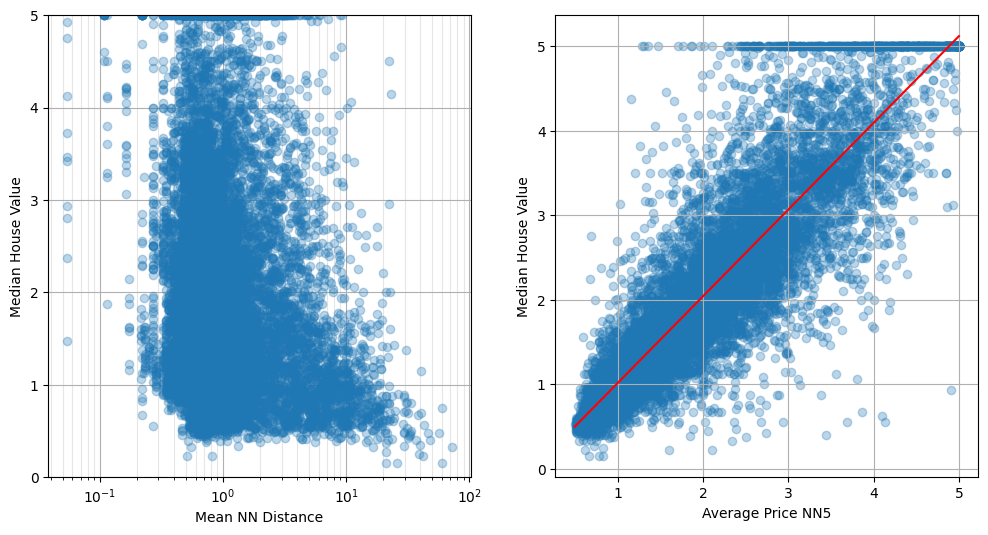

In [32]:
### plot the two NN features
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

#fit mean dist nn
slope, intercept = np.polyfit((X_train["MeanNNDist"]), y_train, 1)
x = np.linspace(X_train["MeanNNDist"].min(), X_train["MeanNNDist"].max(), 100)
y = slope * x + intercept

axs[0].semilogx(X_train["MeanNNDist"], y_train, 'o', alpha=0.3)
#axs[0].plot( x,y, color ="red")
axs[0].set_xlabel("Mean NN Distance")
axs[0].set_ylabel("Median House Value")
axs[0].set_ylim(0,5)
axs[0].grid()
axs[0].grid(which = "minor", color = "0.9")

#fit average price knn
slope, intercept = np.polyfit(X_train["AveragePriceNN5"], y_train, 1)
x = np.linspace(X_train["AveragePriceNN5"].min(), X_train["AveragePriceNN5"].max(), 100)
y = slope * x + intercept

axs[1].scatter(X_train["AveragePriceNN5"], y_train, alpha=0.3)
axs[1].plot(x,y, color = 'red')
axs[1].set_xlabel("Average Price NN5")
axs[1].set_ylabel("Median House Value")
axs[1].grid()
axs[1].grid(which = "minor", color = "0.9")

plt.show()

It's apparent that both nearest neighbors features created have correlation with house price. The Out of fold KNN5 House price feature has a very strong correlation, this is to be expected as the price of close by houses should be a clear indicator for price of other houses in the same area. We also see a slight negative correlation with our distance to nearest neighbors feature, this suggests that more rural/spaced out properties could tend to be cheaper, another useful feature to consider.

#### **8) Preprocessing**

we have some heavily right skewed features, these will be logged before scaling as they will be harder to view by the model after scaling due to the skewed effect on the scalers standard deviation.

The original run was done with the area feature used for visualisation. This was dropped for the more precise Dist features due to better performance. The area feature was originally OneHotEncoded, the refined run does not need to use onehot encoding.

In [33]:
#List of numerical features that aren't right skewed and can justbe scaled
numerical_features = ["MedInc",
                      "HouseAge",
                      "AveRooms",
                      "AveBedrms",
                      "BedroomsPerRoom",
                      "AveragePriceNN5",
                      "Latitude",
                      "Longitude",
                      "MeanNNDist" ]

#List of right skewed features
skewed_features = ["Population",
                   "AveOccup",
                   "RoomsPerPerson",
                   "NumberOfHouseholds",
                   "DistCoast",
                   "DistSF",
                   "DistLA",
                   "DistSanDiego"]

#Features that need encoded such as area (dropped this in favour of distance based features)
categorical_features = []

In [34]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

#define log then scale pipeline feature
log_scale_pipeline = Pipeline([
    ("log", FunctionTransformer(
        np.log1p,
        feature_names_out = "one-to-one")),
    ("scale", StandardScaler())
])

#Create the preprocessor column transformer
preprocessor = ColumnTransformer(
    transformers = [
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(), categorical_features),
        ("log", log_scale_pipeline, skewed_features)
    ]
)

X_train_preprocessed = preprocessor.fit_transform(X_train)
X_val_preprocessed = preprocessor.transform(X_val)
X_test_preprocessed = preprocessor.transform(X_test)

In [35]:
#column names
feature_names = preprocessor.get_feature_names_out()

### **9) Creating a Raw Bassline**
We can compare out feature engineered data with a bassline model train on the raw features, this will show how much the feature engineering has helped the model to learn

In [36]:
raw_cols = ["MedInc", "HouseAge", "AveRooms", "AveBedrms",
            "Population", "AveOccup", "Latitude", "Longitude"]

baseline_pre = ColumnTransformer(
    [("scale", StandardScaler(), raw_cols)], remainder="drop"
).set_output(transform="pandas")

X_train_base = baseline_pre.fit_transform(X_train)
X_val_base = baseline_pre.transform(X_val)
X_test_base = baseline_pre.transform(X_test)

### **10) The Model**
The model used will utilise a residual connection and an inverted bottleneck structure. The neural network will contain 5 layers, going from 32 - 64 - 128 - 64 - 32 neurons and using a residual connection from the first set of neurons to the last. I will add in a dropout layer to try and prevent overfitting, this will be adjustable for fine tuning of the model. The adam optimiser will be equipped with a learning rate decay to  improve performance and early stopping will also be implemented to prevent overfitting.

In [37]:
def NN_model(X_in, dropout = 0.05):
  #building a model using inverted bottle necks and residual connections
  inputs = tf.keras.layers.Input(shape=(X_in.shape[1],))

  #create first layer which will also be the shortcut
  residual_shortcut = tf.keras.layers.Dense(32)(inputs)
  residual_shortcut = tf.keras.layers.Activation("gelu")(residual_shortcut)
  residual_shortcut = tf.keras.layers.Dropout(dropout)(residual_shortcut)

  #create inverted bottle neck by increasing number of nodes
  X = tf.keras.layers.Dense(64)(residual_shortcut)
  X = tf.keras.layers.Activation("gelu")(X)
  X = tf.keras.layers.Dropout(dropout)(X)

  #create inverted bottle neck by increasing number of nodes
  X = tf.keras.layers.Dense(128)(X)
  X = tf.keras.layers.Activation("gelu")(X)
  X = tf.keras.layers.Dropout(dropout)(X)

  #create inverted bottle neck by increasing number of nodes
  X = tf.keras.layers.Dense(64)(X)
  X = tf.keras.layers.Activation("gelu")(X)
  X = tf.keras.layers.Dropout(dropout)(X)

  #add layer reducing features to match shortcut size
  X = tf.keras.layers.Dense(32)(X)
  X = tf.keras.layers.Activation("gelu")(X)
  X = tf.keras.layers.Dropout(dropout)(X)

  #connect residual block
  residual_added = tf.keras.layers.Add()([residual_shortcut, X])

  residual_output_block = tf.keras.layers.Activation("gelu")(residual_added)

  outputs = tf.keras.layers.Dense(
      1, activation = 'gelu'
      )(residual_output_block)

  return tf.keras.Model(inputs=inputs, outputs= outputs)

#create model
feature_model = NN_model(X_train_preprocessed)
bassline_model = NN_model(X_train_base)

feature_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 17)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        576 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32)        │          0 │ dense[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      2,112 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 64)        │          0 │ dense_1[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │      8,320 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 128)       │          0 │ dense_2[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64)        │          0 │ dense_3[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 32)        │      2,080 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 32)        │          0 │ dense_4[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 32)        │          0 │ activation_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32)        │          0 │ dropout[0][0],    │
│                     │                   │            │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 32)        │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │         33 │ activation_5[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,377 (83.50 KB)

 Trainable params: 21,377 (83.50 KB)

 Non-trainable params: 0 (0.00 B)

### **11) Using Huber Loss function**

Huber loss combines MSE and MAE, for small errors it behaves like MSE and for a large error it behaves like MAE. Here a very wrong prediction is penalised in proportion to its size and not to its square. Using Huber loss combines the advantages of MSE and MAE loss and so is particularly useful for regression problems. The delta (point at which the loss switches) will have to be fine tuned. on running experiments i found that the best delta was 0.3.

In [38]:
#defining Huber loss with 0.3 threshold
loss = keras.losses.Huber(0.3)

In [39]:
#compile the models with mse loss
feature_model.compile(
    optimizer = tf.keras.optimizers.Adam(),
    loss = loss,
    metrics = ["mae"])

bassline_model.compile(
    optimizer = tf.keras.optimizers.Adam(),
    loss = loss,
    metrics = ["mae"])

In [40]:
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_delta=1e-4,
    min_lr=1e-6,
    verbose=1,
)

### Adjusted early stopping delta
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=12,
    restore_best_weights=True,
    min_delta = 0.0001
)

### **12) Train the Model**

In [41]:


history_feat = feature_model.fit(
    X_train_preprocessed,
    y_train,
    validation_data = (X_val_preprocessed, y_val),
    epochs = 100,
    batch_size = 32,
    callbacks = [early_stopping, reduce_lr],
    verbose = 1
)

history_base = bassline_model.fit(
    X_train_base,
    y_train,
    validation_data = (X_val_base, y_val),
    epochs = 100,
    batch_size = 32,
    callbacks = [early_stopping, reduce_lr],
    verbose = 1
)

Epoch 1/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.1110 - mae: 0.4920 - val_loss: 0.0635 - val_mae: 0.3227 - learning_rate: 0.0010
Epoch 2/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0648 - mae: 0.3296 - val_loss: 0.0588 - val_mae: 0.3047 - learning_rate: 0.0010
Epoch 3/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0619 - mae: 0.3184 - val_loss: 0.0585 - val_mae: 0.3027 - learning_rate: 0.0010
Epoch 4/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0589 - mae: 0.3072 - val_loss: 0.0571 - val_mae: 0.2978 - learning_rate: 0.0010
Epoch 5/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0581 - mae: 0.3037 - val_loss: 0.0561 - val_mae: 0.2924 - learning_rate: 0.0010
Epoch 6/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0565 - mae: 0.2980 - val_loss: 0.0546 - val_mae: 0.2873 - learning_rate: 0.0010
Epoch 7/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0557 - mae: 0.2946 - val_loss: 0.0567 - val_mae: 0.2949 - learning_rate: 0.0010

### **13) Loss Curves**

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0469 - mae: 0.2564
Test MAE: 0.256  (≈ $25,640)


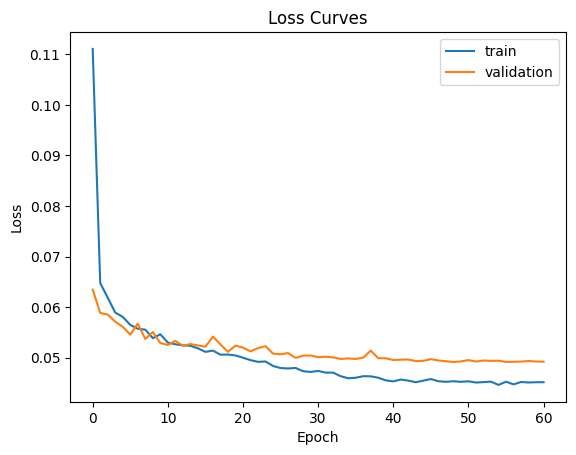

In [42]:
def eval_plot(model, history, X, y):

  test_loss, test_mae = model.evaluate(X, y)
  print(f"Test MAE: {test_mae:.3f}  (≈ ${test_mae * 100_000:,.0f})")


  plt.plot(history.history["loss"], label="train")
  plt.plot(history.history["val_loss"], label="validation")
  plt.title("Loss Curves")
  plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()

eval_plot(feature_model, history_feat, X_test_preprocessed, y_test)


129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0967 - mae: 0.4463
Test MAE: 0.446  (≈ $44,628)


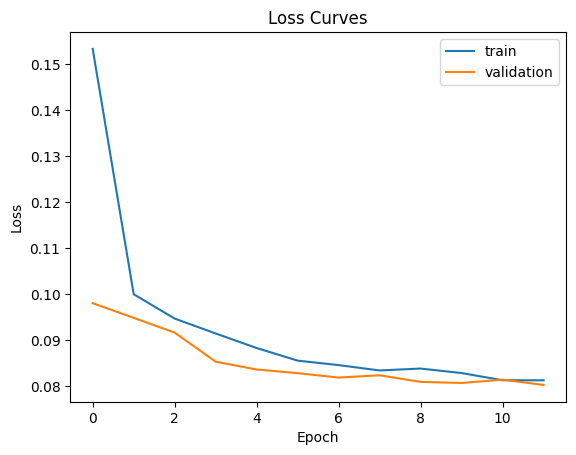

In [43]:
eval_plot(bassline_model, history_base, X_test_base, y_test)

### **14) Model Analysis**

In [44]:
#getting predictions
y_pred_feat_test = feature_model.predict(X_test_preprocessed, verbose = 0).ravel()
y_pred_base_test = bassline_model.predict(X_test_base, verbose = 0).ravel()
y_pred_feat_train = feature_model.predict(X_train_preprocessed, verbose = 0).ravel()
y_pred_base_train = bassline_model.predict(X_train_base, verbose = 0).ravel()

##### **14.1) Performance Metrics**

The house prices are clipped at 5, this check jst puts anything above 5 to 5 as a sanity check

In [45]:
def clipped_eval(model, X_test, y_test, preds):
  preds = model.predict(X_test, verbose=0).ravel()
  preds_clipped = np.clip(preds, 0, 5)

  mae_raw = np.abs(preds - np.asarray(y_test)).mean()
  mae_clipped = np.abs(preds_clipped - np.asarray(y_test)).mean()
  print(f"Raw MAE: {mae_raw:.4f}   Clipped MAE: {mae_clipped:.4f}")

clipped_eval(feature_model, X_test_preprocessed, y_test, y_pred_feat_test)
clipped_eval(bassline_model, X_test_base, y_test, y_pred_base_test)

Raw MAE: 0.2564   Clipped MAE: 0.2560
Raw MAE: 0.4463   Clipped MAE: 0.4423


In [46]:
from sklearn.metrics import mean_absolute_percentage_error, root_mean_squared_error


def MAPE_RMSE(y_test, y_preds_train, y_preds_test):

    MAPE_train = mean_absolute_percentage_error(y_train, y_preds_train)
    MAPE_test = mean_absolute_percentage_error(y_test, y_preds_test)

    RMSE_train = root_mean_squared_error(y_train, y_preds_train)
    RMSE_test = root_mean_squared_error(y_test, y_preds_test)

    print(f"Train MAPE :{round(MAPE_train*100, 2)}%")
    print(f"Train RMSE :{round(RMSE_train, 2)}")

    print(f"Test MAPE : {round(MAPE_test*100, 2)}%")
    print(f"Train RMSE : {round(RMSE_test, 2)}")
    return MAPE_train, MAPE_test, RMSE_train, RMSE_test

print("Model with Engineered Features")
MAPE_train_feat, MAPE_test_feat, RMSE_train_feat, RMSE_test_feat = MAPE_RMSE(y_test, y_pred_feat_train, y_pred_feat_test)
print("\nBassline Model with Original Features")
MAPE_train_base, MAPE_test_base, RMSE_train_base, RMSE_test_base = MAPE_RMSE(y_test, y_pred_base_train, y_pred_base_test)

Model with Engineered Features
Train MAPE :12.88%
Train RMSE :0.38
Test MAPE : 13.99%
Train RMSE : 0.41

Bassline Model with Original Features
Train MAPE :23.36%
Train RMSE :0.64
Test MAPE : 24.47%
Train RMSE : 0.66


The RMSE being moderatly higher than the MAE suggests that there is variation in error magnitude.

##### **14.2) Residuals Plots**

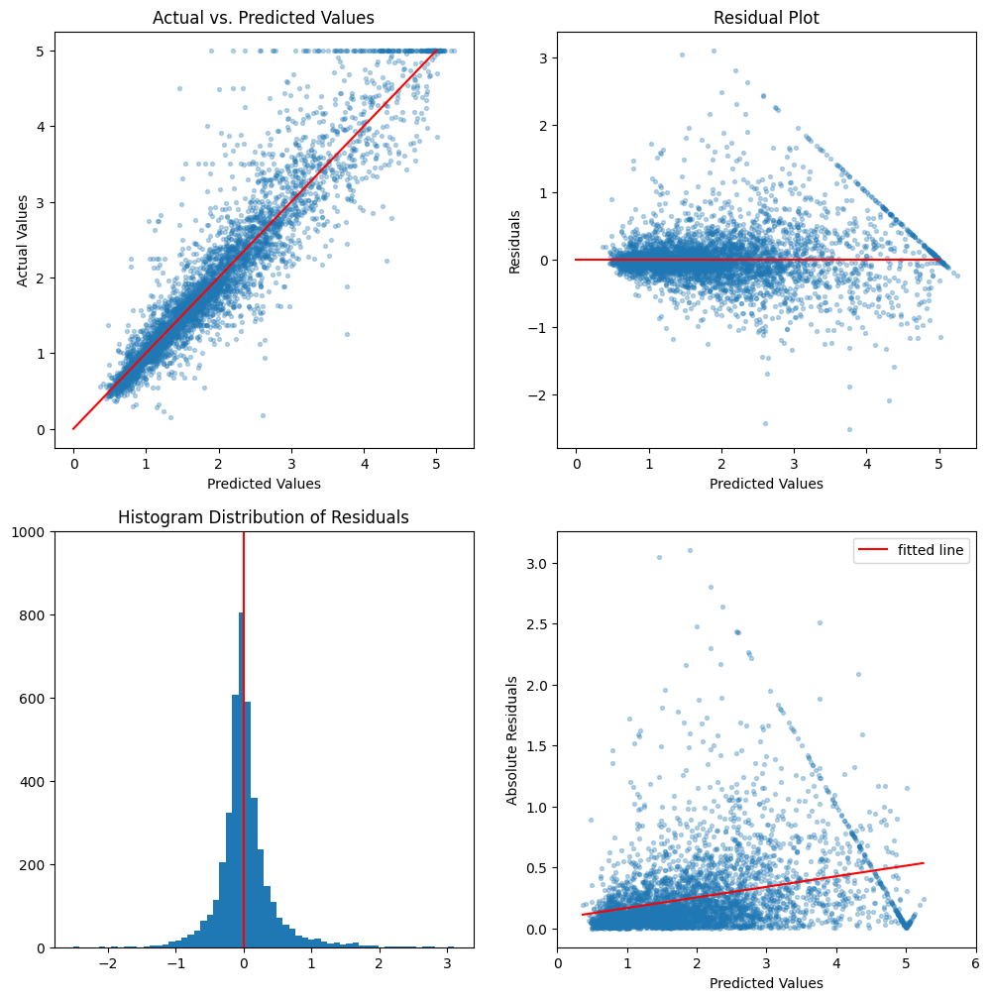

In [47]:


def residual_plot(model, X_test, y_test, y_pred):

  actual = np.array(y_test)
  residuals = actual - y_pred
  abs_residuals = np.abs(residuals)

  fig, axs = plt.subplots(2, 2, figsize = (12, 12))

  axs = axs.flatten()

  axs[1].scatter(y_pred, residuals, alpha = 0.3, s = 8)
  axs[1].plot([0,5], [0,0], color = "red")
  axs[1].set_xlabel("Predicted Values")
  axs[1].set_ylabel("Residuals")
  axs[1].set_title("Residual Plot")

  axs[0].scatter(y_pred, y_test, alpha = 0.3, s = 8)
  axs[0].plot([0, 5], [0, 5], color = "red")
  axs[0].set_xlabel("Predicted Values")
  axs[0].set_ylabel("Actual Values")
  axs[0].set_title("Actual vs. Predicted Values")

  axs[2].set_title("Histogram Distribution of Residuals")
  axs[2].hist(residuals, bins =60)
  axs[2].axvline(0, color = "red")
  axs[2].set_ylim(0,1000)
  #absolute residuals fit
  slope, intercept = np.polyfit(y_pred, abs_residuals, 1)
  x = np.linspace(y_pred.min(), y_pred.max(), 100)
  y = slope * x + intercept
  #absolute residuals scatter
  axs[3].scatter(y_pred, abs_residuals, alpha = 0.3, s = 8)
  axs[3].plot(x, y, color = "red", label = "fitted line")
  axs[3].set_xlabel("Predicted Values")
  axs[3].set_ylabel("Absolute Residuals")
  axs[3].set_xlim(0,6)
  axs[3].legend()
  plt.show()

residual_plot(feature_model, X_test_preprocessed, y_test, y_pred_feat_test)

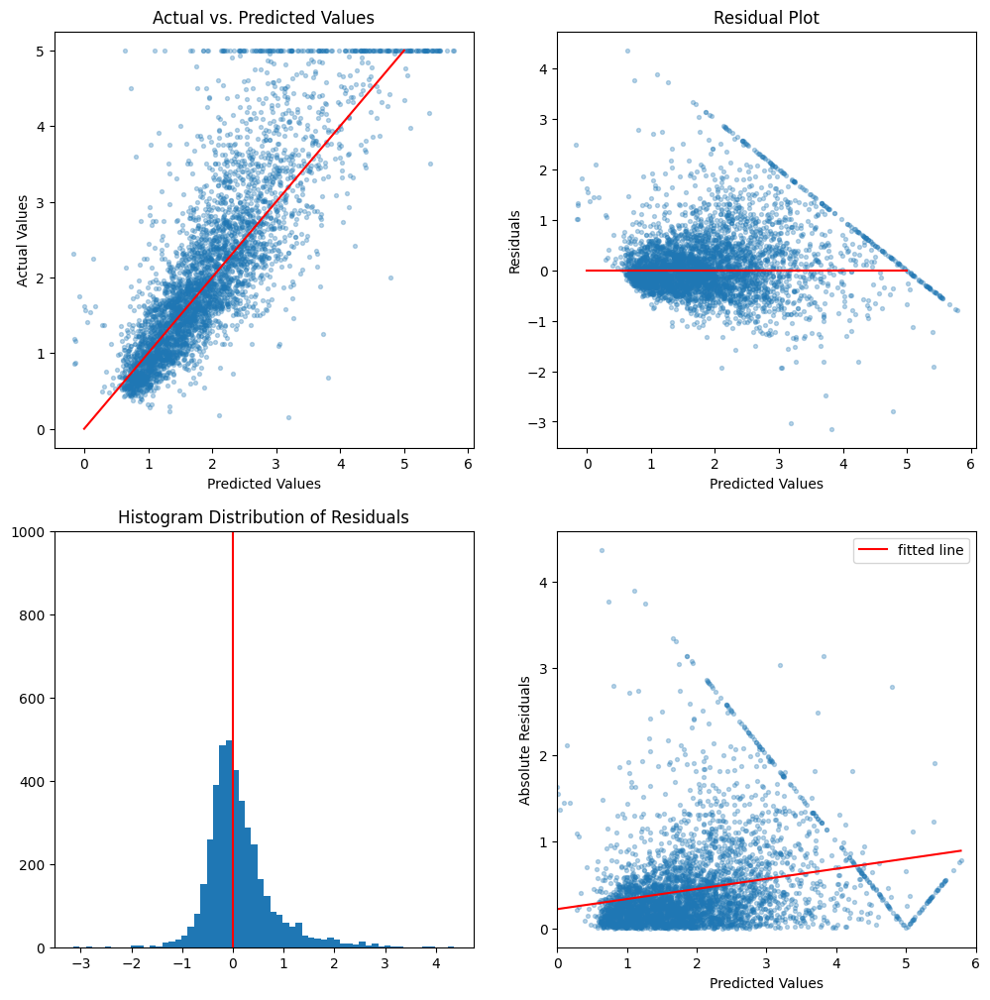

In [48]:
residual_plot(bassline_model, X_test_base, y_test, y_pred_base_test)

We can see that the model has tendancy to underpredict on values as seen on the residuals histomgram plot. Across both models there are larger wrong predictions for larger absolute values of the residuals which is to be expected when considering the proportionality of the error. We can see the effect of the 5. price cap here, with a straight line of points showing where y_actual = 5 with some predictions reaching over this.

##### **14.3) Worst Predictions**

Looking at the worst predictions can give us some information on where the model is going worng. Comparing these to worst predictions from different models can give us an idea of the weaknessess across models, and how ensembling could lead to different results.

In [49]:
def worst_predictions(y_test, y_pred, X_test):
    predictions = pd.DataFrame({
        "Actual": y_test,
        "Predictions": y_pred
    })

    predictions["Error"] = predictions["Actual"] - predictions["Predictions"]
    predictions["Absolute Error"] = np.abs(predictions["Error"])

    X_test_df = pd.DataFrame(
        X_test,
        columns = X_test.columns,
        index = X_test.index
    )

    worst_predictions = pd.concat([
        X_test_df.reset_index(drop = True),
        predictions.reset_index(drop = True)
    ], axis = 1)

    worst_predictions = worst_predictions.sort_values(
        by = "Absolute Error",
        ascending = False
    ).head(10)

    return worst_predictions

worst_predictions_features = worst_predictions(y_test, y_pred_feat_test, X_test)

print("Worst Predictions")
display(worst_predictions_features)

Worst Predictions


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,RoomsPerPerson,BedroomsPerRoom,...,DistCoast,DistSF,DistLA,DistSanDiego,AveragePriceNN5,MeanNNDist,Actual,Predictions,Error,Absolute Error
872,3.7727,24.0,10.953586,1.848101,473.0,1.995781,33.75,-116.43,5.488372,0.168721,...,67.219588,701.392486,170.726912,133.606114,1.979900,2.201248,5.00001,1.896047,3.103963,3.103963
3710,1.7679,39.0,5.000000,0.888889,22.0,2.444444,37.63,-120.92,2.045455,0.177778,...,38.259594,132.891765,465.205348,644.313215,1.232900,1.776028,4.50000,1.455430,3.044570,3.044570
1140,1.9659,6.0,4.795455,1.159091,125.0,2.840909,33.72,-117.70,1.688000,0.241706,...,13.060623,620.051708,62.316097,122.408553,2.485600,3.387473,5.00001,2.198013,2.801997,2.801997
3693,4.2386,6.0,7.723077,1.169231,228.0,3.507692,33.83,-117.55,2.201754,0.151394,...,24.322799,620.503470,68.596813,129.071259,1.855000,2.205401,5.00001,2.362185,2.637825,2.637825
285,7.3004,32.0,5.724138,0.758621,63.0,2.172414,34.17,-119.08,2.634921,0.132530,...,4.773658,500.899297,78.099195,240.511222,2.275000,3.743125,1.25000,3.760309,-2.510309,2.510309
4060,6.3406,41.0,7.601770,1.076696,913.0,2.693215,38.58,-121.39,2.822563,0.141638,...,33.845253,126.926556,576.915430,755.563170,1.292200,0.853464,4.48300,2.006651,2.476349,2.476349
1865,1.1696,52.0,2.436000,0.944000,1349.0,5.396000,37.87,-122.25,0.451446,0.387521,...,2.979461,18.254106,556.858955,735.790813,3.429900,0.683028,5.00001,2.567595,2.432415,2.432415
2927,2.3667,39.0,3.572464,1.217391,259.0,1.876812,34.15,-118.33,1.903475,0.340771,...,13.595717,545.702743,13.468577,192.873105,3.326702,0.851919,0.17500,2.601113,-2.426113,2.426113
1649,0.4999,28.0,7.677419,1.870968,142.0,4.580645,34.15,-118.08,1.676056,0.243697,...,25.071828,561.106345,18.586222,180.848323,3.045500,0.857912,5.00001,2.574530,2.425480,2.425480
3224,1.7306,28.0,2.837097,1.154839,1463.0,2.359677,34.10,-118.32,1.202324,0.407049,...,11.641799,550.499658,8.811055,187.786768,2.263400,0.400499,4.50000,2.199300,2.300700,2.300700


The worst predictions seem to represent extreme cases, where the actual value of the house is close to the max of 5 and the model is tending to over underpredict these values. They seem to show the models reliance on the average price KNN feature, with most predictions being a lot closer to that feature than the actual value.

In [50]:
NN_price_diff = (worst_predictions_features["AveragePriceNN5"] - worst_predictions_features["Predictions"]).abs().mean()
Act_price_diff = (worst_predictions_features["Actual"] - worst_predictions_features["Predictions"]).abs().mean()
print(f"Average NN Price Difference: {NN_price_diff:.2f}")
print(f"Average Actual Price Difference: {Act_price_diff:.2f}")


Average NN Price Difference: 0.54
Average Actual Price Difference: 2.62


##### **Worst Predictions Bassline**

In [51]:
worst_predictions_base = worst_predictions(y_test, y_pred_base_test, X_test[raw_cols])

print("Worst Predictions Baseline")
display(worst_predictions_base)

Worst Predictions Baseline


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Actual,Predictions,Error,Absolute Error
1649,0.4999,28.0,7.677419,1.870968,142.0,4.580645,34.15,-118.08,5.00001,0.635758,4.364252,4.364252
1865,1.1696,52.0,2.436000,0.944000,1349.0,5.396000,37.87,-122.25,5.00001,1.103323,3.896687,3.896687
3710,1.7679,39.0,5.000000,0.888889,22.0,2.444444,37.63,-120.92,4.50000,0.736341,3.763659,3.763659
1140,1.9659,6.0,4.795455,1.159091,125.0,2.840909,33.72,-117.70,5.00001,1.259099,3.740911,3.740911
1138,0.9000,52.0,2.237474,1.053535,3260.0,2.237474,37.80,-122.41,5.00001,1.657725,3.342285,3.342285
3693,4.2386,6.0,7.723077,1.169231,228.0,3.507692,33.83,-117.55,5.00001,1.694993,3.305017,3.305017
1250,7.5752,52.0,3.142857,1.000000,55.0,7.857143,34.02,-118.21,0.67500,3.817208,-3.142208,3.142208
3761,2.3674,20.0,2.740554,1.047859,2919.0,2.450882,34.07,-118.31,5.00001,1.857996,3.142014,3.142014
3972,3.9934,18.0,4.857143,0.809524,55.0,2.619048,34.08,-118.68,5.00001,1.859144,3.140866,3.140866
872,3.7727,24.0,10.953586,1.848101,473.0,1.995781,33.75,-116.43,5.00001,1.923739,3.076271,3.076271


In the Bassline model we're also seeing that the capped max values are the hardest for the model to predict on. This shows us that the bassline model also tends to be underpredicting on the points. We only have one Major overprediction which is surprising, here its clear to see why the model may overpredict as the MedInc is high and also the houses are pretty huge in size having 132 AveRooms so can see why the model might think it would be a valuable property.

##### **14.4) Permutation Importaces**

Generating permutation importances can be a good way of viewing which features the model is preferring. Here we will randomly shuffle one feature at a time then measure the effect that this has on the predictions MAE.

In [52]:
from sklearn.metrics import mean_absolute_error
from sklearn.inspection import permutation_importance


def feature_importance(model, X, y, feature_names):

    baseline_preds = model.predict(X, verbose=0).flatten()
    baseline_mae = mean_absolute_error(y, baseline_preds)

    importances = []

    for i in range(X.shape[1]):

        X_permuted = X.copy()

        # Shuffle one feature
        np.random.shuffle(X_permuted[:, i])

        # Predict using shuffled feature
        predictions = model.predict(X_permuted, verbose=0).flatten()

        # Measure deterioration in performance
        shuffled_mae = mean_absolute_error(y, predictions)

        importances.append(shuffled_mae - baseline_mae)

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False)

    return importance_df


importance_df = feature_importance(feature_model, X_test_preprocessed, y_test, feature_names)

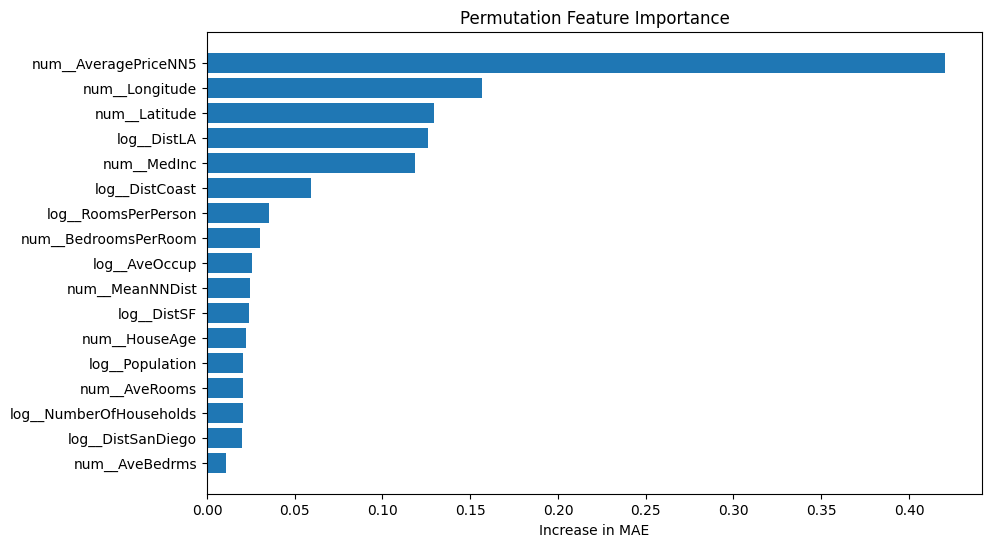

In [53]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Increase in MAE")
plt.title("Permutation Feature Importance")
plt.gca().invert_yaxis()
plt.show()

From the permutation importances it's clear that the AveragePriceNN5 feature had the most importance for the model when predicting house prices. This is as expeced, the model seemed to be relying on NN houseprice for quite a few of the worst predictions and in general it's performance dramatically improved after I added it in during experimentation.

Interestingly Latitude and longitude are second in predicting house price, above the engineered locational features. The added features for location are quite localised, i.e they would only be of relevanceif the record was within a reasonable diatance of the point, this means this means that while their permutation importance is measured against the entire dataset, their actual importance is more relative to the point they represent where there will be substantially less data. I will investigate if they have an effect on a small proportion of the data, and less of an effect on the data when seen as a whole.

Population and ave bedrooms seem to have little to know effect on the predicting power of the model ncreasing MAE by 0.01 when permutated. These could potentially be dropped from the model entirely.

In [54]:
X_test_base_arr = np.array(X_test_base)

In [55]:
feature_importance_bassline = feature_importance(bassline_model, X_test_base_arr, y_test, raw_cols)

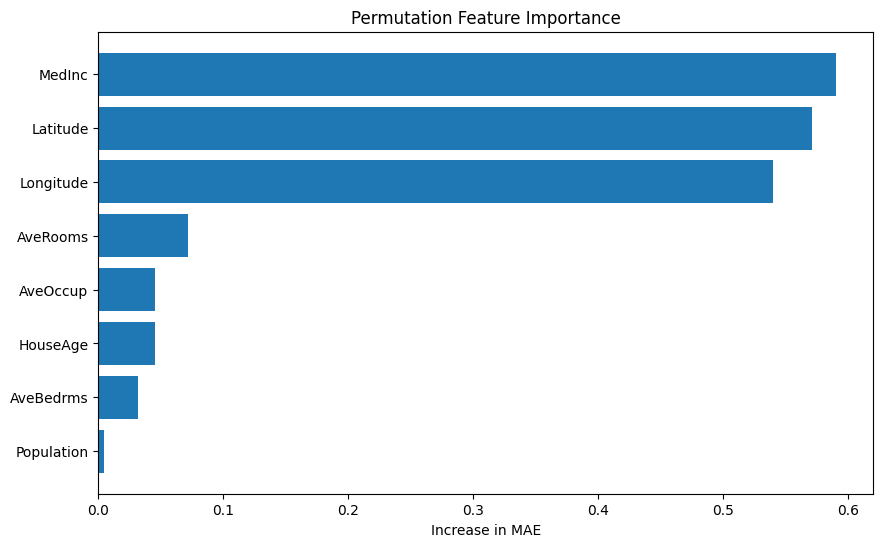

In [56]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance_bassline["Feature"],
    feature_importance_bassline["Importance"]
)

plt.xlabel("Increase in MAE")
plt.title("Permutation Feature Importance")
plt.gca().invert_yaxis()
plt.show()

Can see that the bassline model relies very heavily on Median Income and latitude and longitude. These features are still very important in the model with engineered features, but more information is taken from the nearest neighbors price feature.

##### **14.5) Feature Importances by Area**

First lets take a look at one area in focus, I'll choose San Francisco.

In [57]:
X_test_anal = X_test.copy()
X_test_anal["Area"] = X_test_anal.apply(
    lambda row: classify_area(
        row["Latitude"],
        row["Longitude"]
    ),
    axis=1
)


def Area_Importances(Area, X, y):

    mask = X["Area"] == Area

    X_Area_preprocessed = preprocessor.transform(X[mask])
    y_Area = y[mask]

    feature_importance_Area = feature_importance(
        feature_model,
        X_Area_preprocessed,
        y_Area,
        feature_names
    )

    return feature_importance_Area

feature_importance_SF = Area_Importances("SF", X_test_anal, y_test)


SF Feature Importance


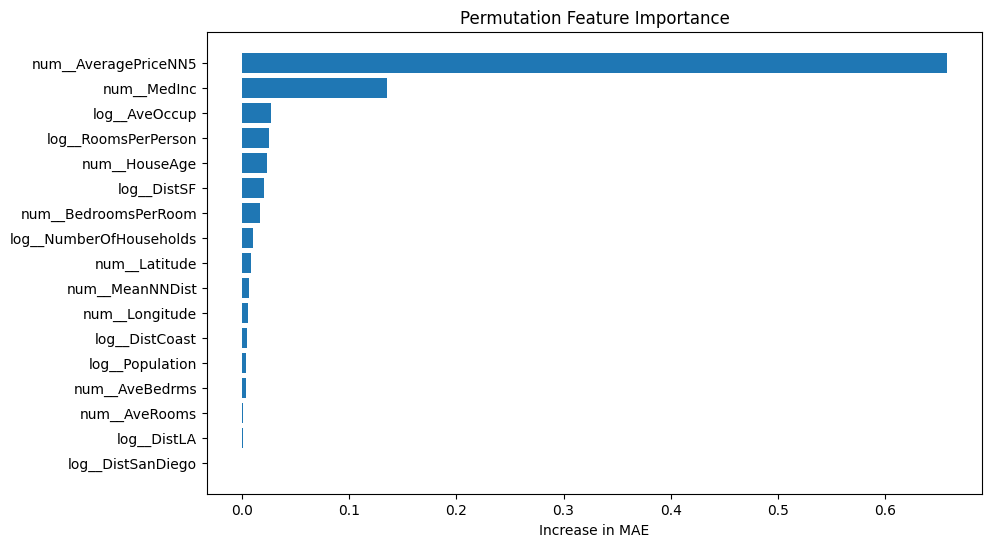

In [58]:
print("SF Feature Importance")

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance_SF["Feature"],
    feature_importance_SF["Importance"]
)

plt.xlabel("Increase in MAE")
plt.title("Permutation Feature Importance")
plt.gca().invert_yaxis()
plt.show()

In [59]:
print(f"Importance around San Francisco = {feature_importance_SF.loc[feature_importance_SF['Feature'] == 'log__DistSF', 'Importance'].iloc[0]}")
print(f"Broader importance = {importance_df.loc[importance_df['Feature'] == 'log__DistSF', 'Importance'].iloc[0]}")

Importance around San Francisco = 0.020515303989766143
Broader importance = 0.024188930833674627


This suggests that the Locational features have somewhat similar importances around the feature they're describing as they do in the broader dataset. We can see the average price feature is dominating the predictions across all datapoints. It is a very powerful feature and is responsible for the majority of the improvements seen in MAE. It's worth noting that in terms of locational features, it's clear that the DistSF feature is actually dominating in this instace, with both longitude and latitude becoming much less influential, this suggests that the model is relying on the SF feature for locational information over latitude and longitude in the SF area.

##### **Broader Look at Features**

In [60]:
#plot all locational data in bar chart
areas = ['Countryside', 'SF', 'Coastal', 'LA', 'SanDiego']

importance_results = []

for area in areas:
    feature_importance_Area = Area_Importances(area, X_test_anal, y_test)

    feature_importance_Area = feature_importance_Area[
        ["Feature", "Importance"]
    ].copy()

    feature_importance_Area["Area"] = area

    importance_results.append(feature_importance_Area)

importance_df_area = pd.concat(importance_results, ignore_index=True)

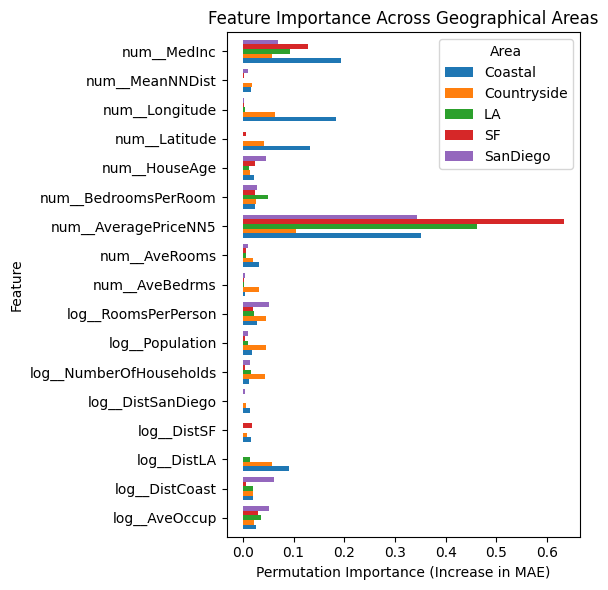

In [61]:
importance_pivot = importance_df_area.pivot(
    index="Feature",
    columns="Area",
    values="Importance"
)

importance_pivot.plot(
    kind="barh",
    figsize=(6, 6),
    width=0.8
)

plt.xlabel("Permutation Importance (Increase in MAE)")
plt.ylabel("Feature")
plt.title("Feature Importance Across Geographical Areas")
plt.legend(title="Area")
plt.tight_layout()
plt.show()

This graph gives the Permutation importances split by the areas initially proposed for one hot encoding locational information. It shows how the model has learned variations across different locations using the features. You can see clearly the dominance of the Average Price NN5 feature.

For Log__DistLA we can see that for house prices in the countryside or on the coast outside of LA, their distance from LA was actually an important feature. Coastal houses relied strongly on Lat and Lon features, suggesting that prices on the coastline also fluctuated quite a bit, with the model relying on coordinate features to make more accurate predictions.

It was in countryside locations where the models reliance on the average price feature was the lowest, this suggests that where there were sparse neighbors there was a bigger disparity in the house prices and other features describing house size and location increased in importance.

Dist Coast was most important for the San Diego Area, this could suggest a more expensive coastal area in the city.

Our engineered rooms per person feature seems influential across all areas, this is interesting as it gives more of a feel for the kind of lives people live, with more rooms per person suggesting ownership of larger houses relative to family size.

The mean distance feature engineered has quite a small effect on MAE when permuted suggesting it wasn't very influential we can see it has its largest effect in the countryside. Here houses are likely to be more spread out and distance between nearest neighbors could carry more information about neighborhood layout than in the cities.



### **15) Conclusions**

The Models Performance with engineered features relating to geospatial distances, surrounding comparable prices and property layout has increased the accuracy of our trained model by an MAE of around 0.2 and a MAPE improvement of around 12% this is a significant improvement, highlighting that feature engineering can be a very influential step in developing a machine learning model. The most important feature by far was the out of fold KNN average price feature, this feature was able to give the model accurate locational price data which is very valuable as neighbors are likely to have similar prices. We have seen that other locational features vary in importance depending on where the properties are situated and have contributed strongly to increasing MAE, before the average price feature was included they carried the most of the MAE increase (experiment done in other notebook). Other engineered features such as rooms per person have also showed a enlarged importance. Overall the model has performed well, we can now look to ensemble it with an XGBoost model trained on the same features to see if we can improve MAE further.

### **16) Ensembling with HistGB**

Lets see how a HistGradeintBoost model performs on the bassline and feature engineered data.

In [62]:
from sklearn.ensemble import HistGradientBoostingRegressor

gb_base = HistGradientBoostingRegressor(
    loss="absolute_error", learning_rate=0.05, max_iter=2000,
    max_leaf_nodes=31, l2_regularization=1.0,
    early_stopping=True, validation_fraction=0.1, n_iter_no_change=30,
    random_state=0,
)
gb_base.fit(X_train_base, y_train)

y_preds_gb_base = gb_base.predict(X_test_base)

mae_gb_base = np.abs(y_preds_gb_base - np.asarray(y_test)).mean()
print(f"Bassline Hist Gradient Boost MAE = {mae_gb_base}")


Bassline Hist Gradient Boost MAE = 0.300163618009112


In [63]:
gb_feat = HistGradientBoostingRegressor(
    loss="absolute_error", learning_rate=0.05, max_iter=2000,
    max_leaf_nodes=31, l2_regularization=1.0,
    early_stopping=True, validation_fraction=0.1, n_iter_no_change=30,
    random_state=0,
)
gb_feat.fit(X_train, y_train)

y_preds_gb = gb_feat.predict(X_test)

mae_gb = np.abs(y_preds_gb - np.asarray(y_test)).mean()
print(f"Hist Gradient Boost with Engineered Featuress {mae_gb}")

Hist Gradient Boost with Engineered Featuress 0.25337541523608687


We can see tha our bassline Hist Gradient Boost Regressor actually performs very well without any engineered features, then with engineered features its performane is marginally improved and sits similar to our trained neural network. The bassline being higher could be explained by the way in which trees draw sharp boundries, Hist gradient boost can draw city limits etc much more effiently from coordinates than a nueral network, I dont have it in this notebook, but on adding locational features the neural networks MAE was imprved to around 0.34-0.3 showing similar performance to the bassline HistGradientBoost model. The average price feature has then given both models that extra boost to get down to an MAE of around 0.25. Ensembling the models should give some of the positives from each model leading to a further improved MAE.

##### **16.2) Worst Predictions HistGB**

In [64]:
worst_predictions_gb = worst_predictions(y_test, y_preds_gb, X_test)

print("Worst Predictions HistGB")
display(worst_predictions_gb)

Worst Predictions HistGB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,RoomsPerPerson,BedroomsPerRoom,...,DistCoast,DistSF,DistLA,DistSanDiego,AveragePriceNN5,MeanNNDist,Actual,Predictions,Error,Absolute Error
3710,1.7679,39.0,5.000000,0.888889,22.0,2.444444,37.63,-120.92,2.045455,0.177778,...,38.259594,132.891765,465.205348,644.313215,1.232900,1.776028,4.50000,1.252195,3.247805,3.247805
1140,1.9659,6.0,4.795455,1.159091,125.0,2.840909,33.72,-117.70,1.688000,0.241706,...,13.060623,620.051708,62.316097,122.408553,2.485600,3.387473,5.00001,1.767040,3.232970,3.232970
872,3.7727,24.0,10.953586,1.848101,473.0,1.995781,33.75,-116.43,5.488372,0.168721,...,67.219588,701.392486,170.726912,133.606114,1.979900,2.201248,5.00001,1.848944,3.151066,3.151066
1649,0.4999,28.0,7.677419,1.870968,142.0,4.580645,34.15,-118.08,1.676056,0.243697,...,25.071828,561.106345,18.586222,180.848323,3.045500,0.857912,5.00001,2.198507,2.801503,2.801503
3693,4.2386,6.0,7.723077,1.169231,228.0,3.507692,33.83,-117.55,2.201754,0.151394,...,24.322799,620.503470,68.596813,129.071259,1.855000,2.205401,5.00001,2.238404,2.761606,2.761606
2558,7.3669,16.0,11.293103,2.727969,873.0,1.672414,32.68,-117.17,6.752577,0.241561,...,0.426108,740.185913,182.269965,4.056077,3.447102,1.185709,1.87500,4.549062,-2.674062,2.674062
4060,6.3406,41.0,7.601770,1.076696,913.0,2.693215,38.58,-121.39,2.822563,0.141638,...,33.845253,126.926556,576.915430,755.563170,1.292200,0.853464,4.48300,1.883440,2.599560,2.599560
2927,2.3667,39.0,3.572464,1.217391,259.0,1.876812,34.15,-118.33,1.903475,0.340771,...,13.595717,545.702743,13.468577,192.873105,3.326702,0.851919,0.17500,2.758644,-2.583644,2.583644
285,7.3004,32.0,5.724138,0.758621,63.0,2.172414,34.17,-119.08,2.634921,0.132530,...,4.773658,500.899297,78.099195,240.511222,2.275000,3.743125,1.25000,3.813692,-2.563692,2.563692
1865,1.1696,52.0,2.436000,0.944000,1349.0,5.396000,37.87,-122.25,0.451446,0.387521,...,2.979461,18.254106,556.858955,735.790813,3.429900,0.683028,5.00001,2.590265,2.409745,2.409745


Once again see most worst predictions having an actual around the max cap of 5 but interestingly they are still all underpredictions. It could be a case that the nature of the cap in the data is causing underpredicting more universally. There's the point with value of 0.175 again in an area with high MedInc and high average price NN can see how the model wouldn't be able to predict on this outlier.

#### **16.3) Permutation iportance in HistGradientBoost**

takes a long time to run

In [65]:
from sklearn.inspection import permutation_importance

def feature_importance(model, X_test, y_test, n_repeats=10):

    result = permutation_importance(
        model,
        X_test,
        y_test,
        n_repeats=n_repeats,
        random_state=42,
        scoring="neg_mean_absolute_error"
    )

    importances = pd.DataFrame({
        "Feature": X_test.columns,
        "Importance": result.importances_mean,
        "Std": result.importances_std
    }).sort_values(by="Importance", ascending=False)

    return importances

baseline_importance = feature_importance(gb_base, X_test_base, y_test)

gb_importance = feature_importance(gb_feat, X_test, y_test)

Added Features Plot


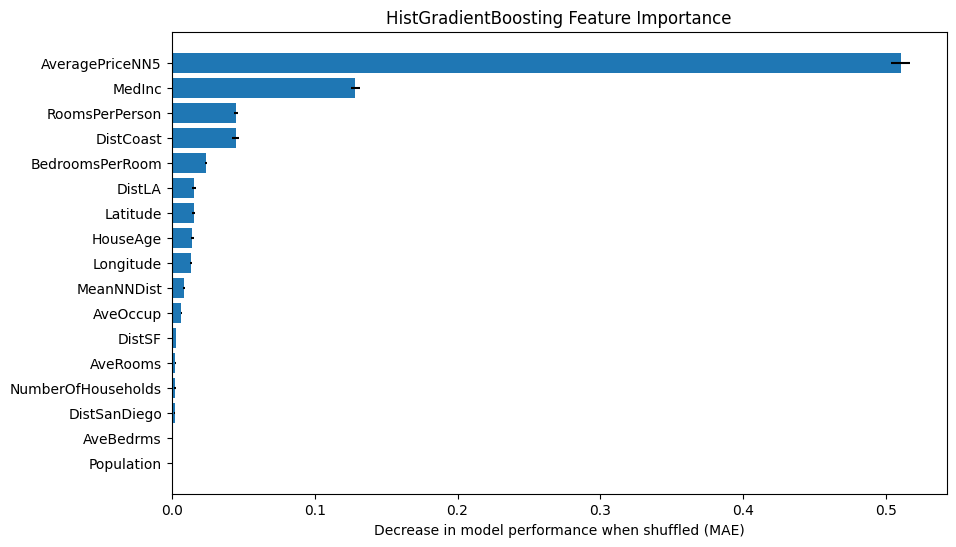

In [66]:
def HistPlot(importances):

    plt.figure(figsize=(10, 6))

    plt.barh(
        importances["Feature"],
        importances["Importance"],
        xerr=importances["Std"]
    )

    plt.gca().invert_yaxis()
    plt.xlabel("Decrease in model performance when shuffled (MAE)")
    plt.title("HistGradientBoosting Feature Importance")
    plt.show()
print("Added Features Plot")
HistPlot(gb_importance)

Bassline Plot


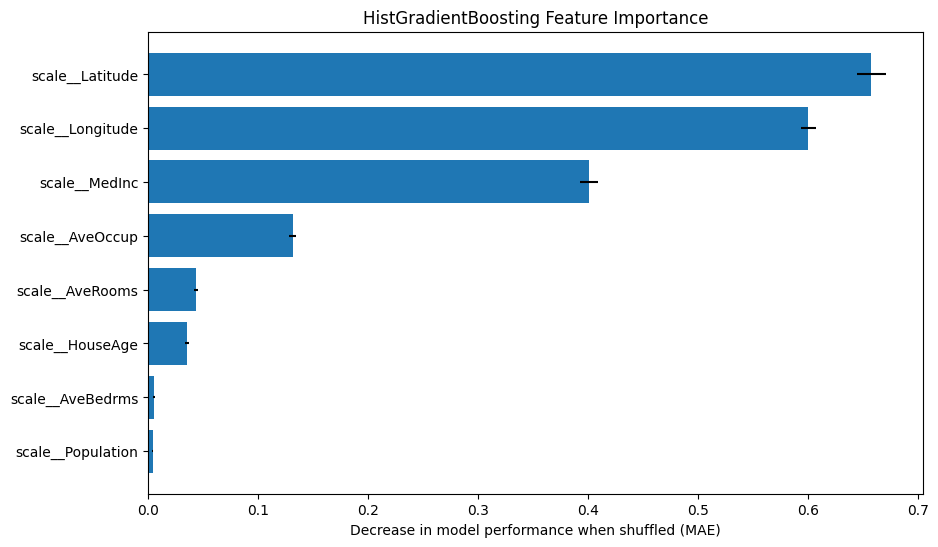

In [67]:
print("Bassline Plot")
HistPlot(baseline_importance)

The Hist Gradient Boost seems to favour our LA and Coast Distance functions over the latitude and longitude which was not seen in the Neural Network. It again shows heavy reliance on the Average price feature, this is where we can attribute the major gains in MAE. The bassline model has a higher reliance on the Longitude and Latitude when compared to the other major feature Median Income, which explains in part its heightened initial performance as the Hist Gradient Boost model was able to pick up on the importance of geographical location.

#### **16.4) Ensembled Model**

In [68]:
y_pred = feature_model.predict(X_test_preprocessed, verbose = 0).ravel()
y_ensemble = (y_pred + y_preds_gb) / 2
mae_ensemble = np.abs(y_ensemble - np.asarray(y_test)).mean()
print(f" The Ensembled MAE for both models is {mae_ensemble}")

 The Ensembled MAE for both models is 0.24961397822967143


#### **17) Final Remarks**

The ensembled model gives a slight improvement on both models suggesting that they each spot different features of the data and the combined model reflects a more smoothed interpretation of the data. Moving forward with an ensembled model promises the best results for house price predictions